<a href="https://colab.research.google.com/github/hadisamuhammadova23-oss/colab-projects/blob/main/Dars_topshirig'i.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kutubxonalar yuklanmoqda...
14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 864ms/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


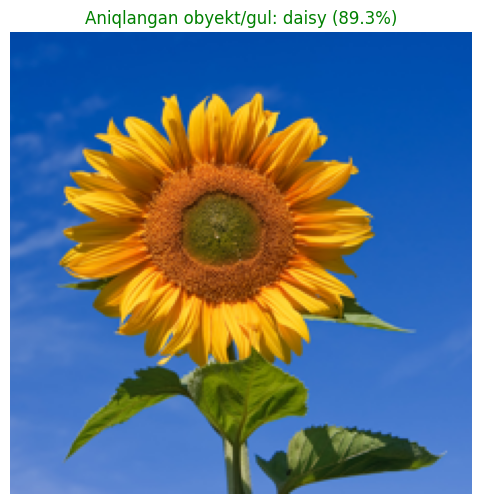


Sun'iy intellekt tahlili natijasi:
Topildi: daisy (Ishonchlilik: 89.3%)


In [1]:
# ==========================================
# Gul va boshqa obyektlarni aniqlovchi to'g'rilangan dastur
# ==========================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import requests
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input, decode_predictions

print("Kutubxonalar yuklanmoqda...")

# 1. Tayyor MobileNetV2 modelini yuklab olamiz (Keras ichidan)
model = MobileNetV2(weights='imagenet')

# 2. Internetdan sinov uchun gul rasmini yuklab olamiz (Masalan: Kungaboqar)
import io

img_url = "https://upload.wikimedia.org/wikipedia/commons/4/40/Sunflower_sky_backdrop.jpg"
headers = {'User-Agent': 'Mozilla/5.0'}
response = requests.get(img_url, headers=headers)
img = Image.open(io.BytesIO(response.content)).resize((224, 224))

# 3. Rasmni model talab qiladigan formatga keltiramiz
x = np.array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

# 4. Bashorat qilish (Modelni ishga tushirish)
preds = model.predict(x)
decoded_preds = decode_predictions(preds, top=1)[0] # Eng yuqori ehtimollikdagi natija

# Natijani ajratib olish
_, gul_nomi, ehtimollik = decoded_preds[0]

# 5. Natijani ekranga chiqarish va rasmni ko'rsatish
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis('off')
plt.title(f"Aniqlangan obyekt/gul: {gul_nomi} ({ehtimollik*100:.1f}%)", fontsize=12, color="green")
plt.show()

print(f"\nSun'iy intellekt tahlili natijasi:")
print(f"Topildi: {gul_nomi} (Ishonchlilik: {ehtimollik*100:.1f}%)")